# Bagian B — Logistic Regression
**Dataset:** Breast Cancer Wisconsin (Diagnostic) dari `scikit-learn`  

## B1. Deskripsi Dataset

Dataset yang digunakan pada Logistic Regression adalah Breast Cancer Wisconsin Diagnostic, yang berasal dari UCI Machine Learning Repository dan tersedia melalui sklearn.datasets.load_breast_cancer(). Dataset ini memiliki 569 baris dan 31 kolom, terdiri dari 30 fitur dan 1 variabel target.

Fitur-fiturnya menggambarkan karakteristik inti sel dari citra jaringan, seperti radius, tekstur, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, dan fractal dimension. Setiap karakteristik memiliki tiga jenis pengukuran, yaitu nilai rata-rata (mean), kesalahan pengukuran (error), dan nilai terburuk (worst).

Variabel target yang diprediksi adalah target, dengan dua kelas, yaitu 0 = malignant (ganas) sebanyak 212 data dan 1 = benign (jinak) sebanyak 357 data. Dataset ini digunakan untuk melatih model agar dapat mengklasifikasikan tumor berdasarkan karakteristik selnya, bukan untuk menggantikan diagnosis medis.


In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    roc_curve, roc_auc_score
)

sns.set_theme()
data = load_breast_cancer(as_frame=True)
df = data.frame.copy()
target_col = "target"
feature_cols = list(data.feature_names)

print(f"Jumlah baris: {df.shape[0]}")
print(f"Jumlah kolom termasuk target: {df.shape[1]}")
print(f"Jumlah fitur: {len(feature_cols)}")
print("Kelas target:", dict(enumerate(data.target_names)))
display(df.head())

Jumlah baris: 569
Jumlah kolom termasuk target: 31
Jumlah fitur: 30
Kelas target: {0: np.str_('malignant'), 1: np.str_('benign')}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


## B2. Eksplorasi dan Visualisasi Data

Tampilkan statistik deskriptif dan distribusi kelas. Tiga visualisasi yang dibuat adalah bar chart kelas target, box plot fitur menurut kelas, serta heatmap korelasi.

In [2]:
display(df.describe().T)
print("Missing values per kolom:")
display(df.isna().sum().to_frame("missing_values"))
print("Jumlah baris duplikat:", int(df.duplicated().sum()))
print("Distribusi kelas (0=malignant, 1=benign):")
display(df[target_col].value_counts().sort_index().rename(index={0:"malignant", 1:"benign"}).to_frame("jumlah"))

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


Missing values per kolom:


,missing_values
mean radius,0
mean texture,0
mean perimeter,0
mean area,0
mean smoothness,0
mean compactness,0
mean concavity,0
mean concave points,0
mean symmetry,0
mean fractal dimension,0


Jumlah baris duplikat: 0
Distribusi kelas (0=malignant, 1=benign):


,jumlah
target,
malignant,212
benign,357


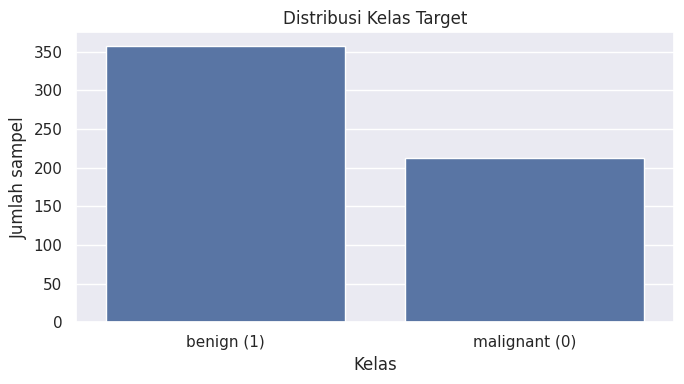

Temuan: bandingkan tinggi kedua batang untuk melihat apakah kelas seimbang.


In [3]:
# Visualisasi 1: distribusi kelas
class_counts = df[target_col].map({0: "malignant (0)", 1: "benign (1)"}).value_counts()
plt.figure(figsize=(7, 4))
sns.barplot(x=class_counts.index, y=class_counts.values)
plt.title("Distribusi Kelas Target")
plt.xlabel("Kelas")
plt.ylabel("Jumlah sampel")
plt.tight_layout()
plt.show()
print("Temuan: bandingkan tinggi kedua batang untuk melihat apakah kelas seimbang.")

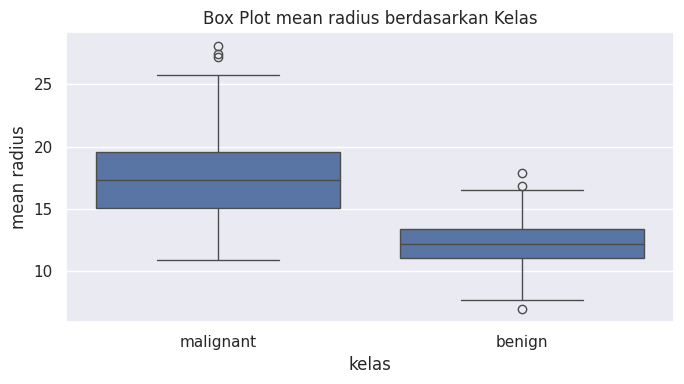

Temuan: bandingkan median, rentang antarkuartil, dan tumpang tindih distribusi antar kelas.


In [4]:
# Visualisasi 2: box plot fitur numerik per kelas
box_feature = "mean radius" if "mean radius" in feature_cols else feature_cols[0]
plot_df = df[[box_feature, target_col]].copy()
plot_df["kelas"] = plot_df[target_col].map({0: "malignant", 1: "benign"})
plt.figure(figsize=(7, 4))
sns.boxplot(data=plot_df, x="kelas", y=box_feature)
plt.title(f"Box Plot {box_feature} berdasarkan Kelas")
plt.tight_layout()
plt.show()
print("Temuan: bandingkan median, rentang antarkuartil, dan tumpang tindih distribusi antar kelas.")

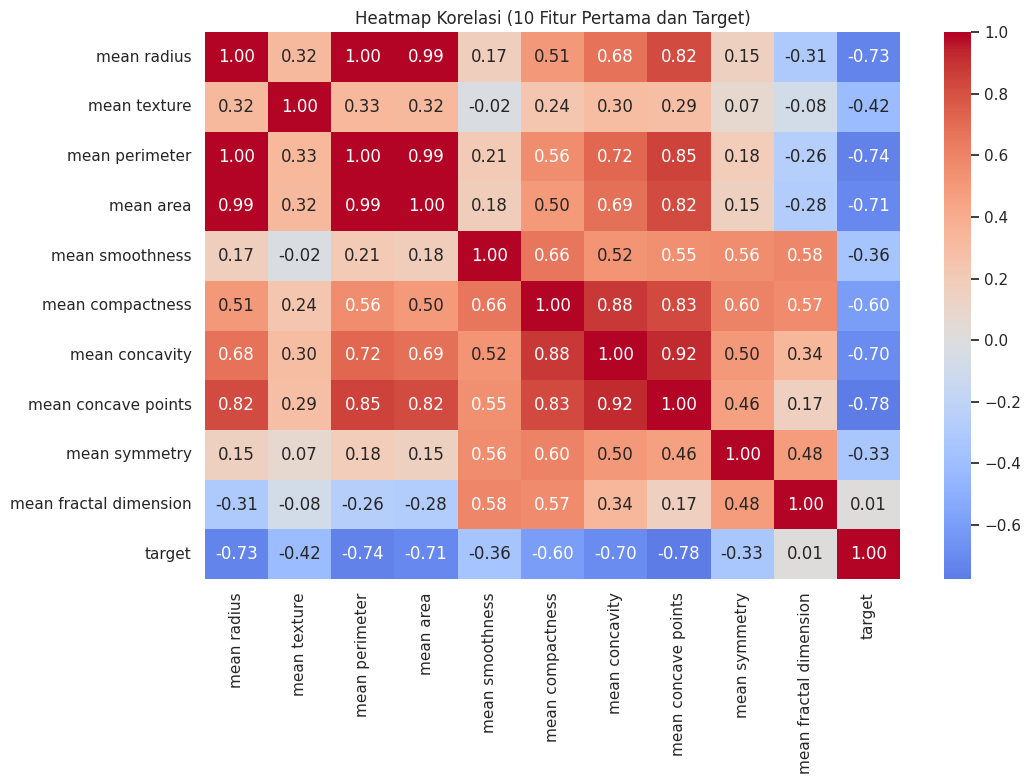

Temuan: korelasi tinggi antarfitur dapat menandakan multikolinearitas; korelasi dengan target menunjukkan asosiasi linear, bukan bukti sebab-akibat.


In [5]:
# Visualisasi 3: heatmap korelasi pada 10 fitur pertama dan target
heat_features = feature_cols[:10] + [target_col]
plt.figure(figsize=(11, 8))
sns.heatmap(df[heat_features].corr(numeric_only=True), cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Heatmap Korelasi (10 Fitur Pertama dan Target)")
plt.tight_layout()
plt.show()
print("Temuan: korelasi tinggi antarfitur dapat menandakan multikolinearitas; korelasi dengan target menunjukkan asosiasi linear, bukan bukti sebab-akibat.")

## B3. Preprocessing

Semua fitur bersifat numerik, sehingga encoding kategori tidak diperlukan. Duplikat diperiksa dan dihapus jika ada. Missing values akan ditangani dengan median melalui pipeline. Outlier ditandai memakai aturan IQR, tetapi tidak langsung dihapus karena pengukuran ekstrem bisa menjadi informasi yang relevan. Fitur diskalakan karena Logistic Regression sensitif terhadap skala.

In [8]:
df_clean = df.copy()
duplicate_count = int(df_clean.duplicated().sum())
if duplicate_count:
    df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print("Duplikat yang ditemukan dan dihapus:", duplicate_count)
print("Ukuran data setelah pemeriksaan duplikat:", df_clean.shape)
print("Total missing values:", int(df_clean.isna().sum().sum()))
print("Encoding kategori tidak diperlukan karena seluruh fitur prediktor numerik.")

outlier_summary = []
for col in feature_cols:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = int(((df_clean[col] < low) | (df_clean[col] > high)).sum())
    outlier_summary.append({"fitur": col, "jumlah_outlier_IQR": count})
outlier_table = pd.DataFrame(outlier_summary).sort_values("jumlah_outlier_IQR", ascending=False)
display(outlier_table.head(10))
print("outlier tidak dihapus otomatis; metode IQR digunakan sebagai penanda untuk pemeriksaan.")

Duplikat yang ditemukan dan dihapus: 0
Ukuran data setelah pemeriksaan duplikat: (569, 31)
Total missing values: 0
Encoding kategori tidak diperlukan karena seluruh fitur prediktor numerik.


,fitur,jumlah_outlier_IQR
13,area error,65
10,radius error,38
12,perimeter error,38
23,worst area,35
14,smoothness error,30
19,fractal dimension error,28
15,compactness error,28
18,symmetry error,27
3,mean area,25
29,worst fractal dimension,24


outlier tidak dihapus otomatis; metode IQR digunakan sebagai penanda untuk pemeriksaan.


## B4. Pemilihan Fitur

Fitur yang saya gunakan yaitu `SelectKBest` dengan `f_classif` untuk memilih 15 fitur berdasarkan hubungan statistik dengan kelas. Pemilihan berlangsung di dalam pipeline setelah scaling dan imputasi. Nilai fitur yang telah diskalakan dapat berupa negatif; `f_classif` dapat digunakan untuk fitur numerik.

## B5. Pembagian Data

Data dibagi 80% latih dan 20% uji dengan `random_state=42`. Parameter `stratify=y` menjaga proporsi kelas pada kedua bagian.

In [9]:
X = df_clean[feature_cols]
y = df_clean[target_col].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Ukuran X_train:", X_train.shape)
print("Ukuran X_test :", X_test.shape)
print("Proporsi kelas data latih:")
display(y_train.value_counts(normalize=True).sort_index().rename(index={0:"malignant", 1:"benign"}).to_frame("proporsi"))
print("Proporsi kelas data uji:")
display(y_test.value_counts(normalize=True).sort_index().rename(index={0:"malignant", 1:"benign"}).to_frame("proporsi"))

Ukuran X_train: (455, 30)
Ukuran X_test : (114, 30)
Proporsi kelas data latih:


,proporsi
target,
malignant,0.373626
benign,0.626374


Proporsi kelas data uji:


,proporsi
target,
malignant,0.368421
benign,0.631579


## B6. Pemodelan

Model memakai `LogisticRegression(max_iter=5000)`. `class_weight='balanced'` tidak diaktifkan secara default karena distribusi kelas perlu diperiksa dahulu dan relatif tidak terlalu timpang; jika analisis menunjukkan ketidakseimbangan bermakna, parameter tersebut dapat diuji sebagai eksperimen pembanding. Kelas positif untuk precision, recall, dan F1 adalah **benign (1)**.

In [11]:
logistic_model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("selector", SelectKBest(score_func=f_classif, k=15)),
    ("classifier", LogisticRegression(max_iter=5000, random_state=42))
])
logistic_model.fit(X_train, y_train)

selector = logistic_model.named_steps["selector"]
selected_features = X_train.columns[selector.get_support()].tolist()
classifier = logistic_model.named_steps["classifier"]

coef_table = pd.DataFrame({
    "fitur_terpilih": selected_features,
    "koefisien": classifier.coef_[0]
}).sort_values("koefisien", key=np.abs, ascending=False)
print("Intercept:", round(float(classifier.intercept_[0]), 4))
display(coef_table)
print("koefisien positif menaikkan log-odds kelas benign (1), sedangkan koefisien negatif menurunkannya, dengan fitur lain tetap.")

Intercept: 0.3188


,fitur_terpilih,koefisien
14,worst concave points,-1.724684
9,worst radius,-1.408573
11,worst area,-1.382200
3,mean compactness,1.176914
5,mean concave points,-1.144149
8,area error,-1.057973
10,worst perimeter,-0.927260
6,radius error,-0.860801
12,worst compactness,-0.673307
13,worst concavity,-0.668284


koefisien positif menaikkan log-odds kelas benign (1), sedangkan koefisien negatif menurunkannya, dengan fitur lain tetap.


## B7. Evaluasi Model

Hitung accuracy, precision, recall, dan F1-score pada data uji. Tampilkan confusion matrix serta ROC curve dan AUC. Karena target 1 adalah benign, metrik standar menganggap benign sebagai kelas positif. Classification report juga menyajikan hasil masing-masing kelas, termasuk malignant.

In [12]:
y_pred = logistic_model.predict(X_test)
y_prob = logistic_model.predict_proba(X_test)[:, 1]

metrics_b = pd.DataFrame([{
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision (benign=1)": precision_score(y_test, y_pred, pos_label=1, zero_division=0),
    "Recall (benign=1)": recall_score(y_test, y_pred, pos_label=1, zero_division=0),
    "F1-score (benign=1)": f1_score(y_test, y_pred, pos_label=1, zero_division=0),
    "ROC-AUC (benign=1)": roc_auc_score(y_test, y_prob)
}])
display(metrics_b.round(4))
print("Classification report:")
print(classification_report(y_test, y_pred, target_names=["malignant (0)", "benign (1)"], zero_division=0))

,Accuracy,Precision (benign=1),Recall (benign=1),F1-score (benign=1),ROC-AUC (benign=1)
0,0.9649,0.9722,0.9722,0.9722,0.9914


Classification report:
               precision    recall  f1-score   support

malignant (0)       0.95      0.95      0.95        42
   benign (1)       0.97      0.97      0.97        72

     accuracy                           0.96       114
    macro avg       0.96      0.96      0.96       114
 weighted avg       0.96      0.96      0.96       114



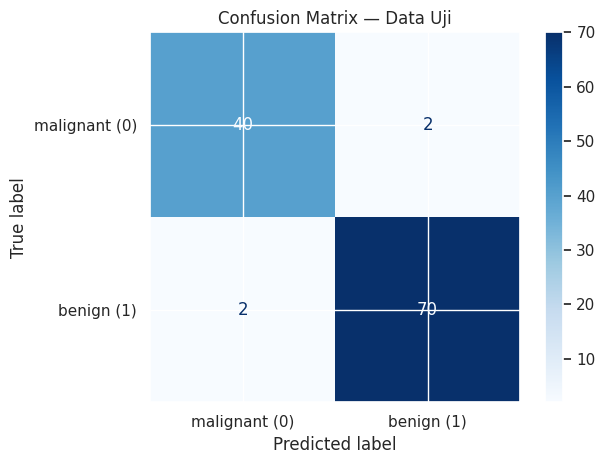

Baris = kelas aktual, kolom = prediksi.


In [15]:
# Confusion matrix: urutan label 0=malignant, 1=benign
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["malignant (0)", "benign (1)"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix — Data Uji")
plt.tight_layout()
plt.show()

print("Baris = kelas aktual, kolom = prediksi.")

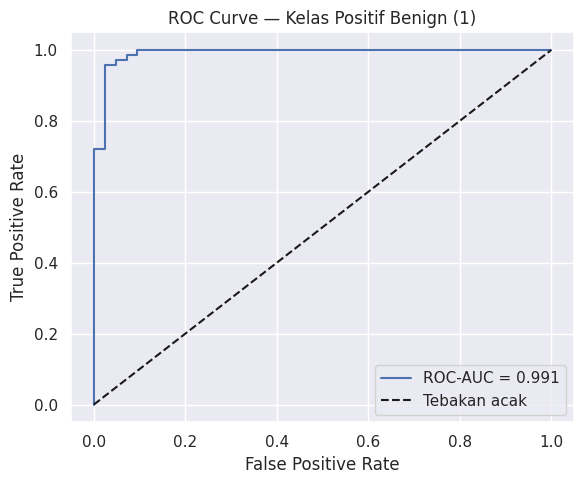

ROC-AUC: 0.9914


In [16]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob, pos_label=1)
auc_value = roc_auc_score(y_test, y_prob)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {auc_value:.3f}")
plt.plot([0, 1], [0, 1], "k--", label="Tebakan acak")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Kelas Positif Benign (1)")
plt.legend()
plt.tight_layout()
plt.show()
print(f"ROC-AUC: {auc_value:.4f}")

## B8. Analisis Performa dan Kesimpulan

Hasil evaluasi menunjukkan bahwa model Logistic Regression mampu mengklasifikasikan tumor ke dalam kategori ganas dan jinak berdasarkan fitur-fitur yang tersedia. Performa model dinilai menggunakan accuracy, precision, recall, dan F1-score untuk mengetahui ketepatan prediksi. Confusion matrix digunakan untuk melihat jumlah prediksi yang benar dan salah pada setiap kelas, sedangkan ROC-AUC digunakan untuk mengukur kemampuan model membedakan tumor ganas dan jinak. Semakin tinggi nilai metrik evaluasi, semakin baik performa model dalam melakukan klasifikasi. Namun, model ini hanya digunakan untuk pembelajaran dan tidak dapat menggantikan diagnosis dari tenaga medis.

In [18]:
print("Ringkasan metrik:")
display(metrics_b.round(4))
print("Confusion matrix (baris aktual [malignant, benign], kolom prediksi [malignant, benign]):")
print(cm)
print("Fitur dengan koefisien absolut terbesar:", coef_table.iloc[0]["fitur_terpilih"])

Ringkasan metrik:


,Accuracy,Precision (benign=1),Recall (benign=1),F1-score (benign=1),ROC-AUC (benign=1)
0,0.9649,0.9722,0.9722,0.9722,0.9914


Confusion matrix (baris aktual [malignant, benign], kolom prediksi [malignant, benign]):
[[40  2]
 [ 2 70]]
Fitur dengan koefisien absolut terbesar: worst concave points
